In [23]:
import pandas as pd
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt

import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import GroupKFold

#### Load and Prepare Data

In [24]:
point = 'p102'
data_pcs = pd.read_csv("outputs/pca/pcs_msl_sel_6h.csv", index_col=0, parse_dates=True)
waves_df_z = pd.read_csv(f"outputs/marginal/z_bulk_{point}.csv", index_col=0, parse_dates=True)   # PIT + armónica (00_PIT)
horas_6h = [0, 6, 12, 18]
waves_df_z_6h = waves_df_z.rolling("6h", center=True).mean()
waves_df_z_6h = waves_df_z_6h[waves_df_z_6h.index.hour.isin(horas_6h)].dropna()

In [25]:
lags = [0, 6, 12, 18, 24, 30, 36]
pcs_msl_lagged = pd.concat({f"l{l}": data_pcs.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(data_pcs.index)
pcs_msl_lagged.columns = [f"{c}_l{l[1:]}" for l, c in pcs_msl_lagged.columns]
pcs_msl_lagged = pcs_msl_lagged.dropna()

idx = pcs_msl_lagged.index.intersection(waves_df_z_6h.index)
X = pcs_msl_lagged.loc[idx]
y = waves_df_z_6h.loc[idx, 'VHM0']

#### CrossValidation

In [26]:
tr = idx < "2016-01-01"
X_tr, y_tr = sm.add_constant(X[tr]), y[tr]

In [27]:
f_oof = pd.Series(np.nan, index=X_tr.index)
for i_fit, i_val in GroupKFold(n_splits=6).split(X_tr, y_tr, groups=X_tr.index.year):
    m = sm.OLS(y_tr.iloc[i_fit], X_tr.iloc[i_fit]).fit()
    f_oof.iloc[i_val] = m.predict(X_tr.iloc[i_val])

#### Full Model

In [28]:
m_final = sm.OLS(y_tr, X_tr).fit()
y_predict = m_final.predict(sm.add_constant(X))

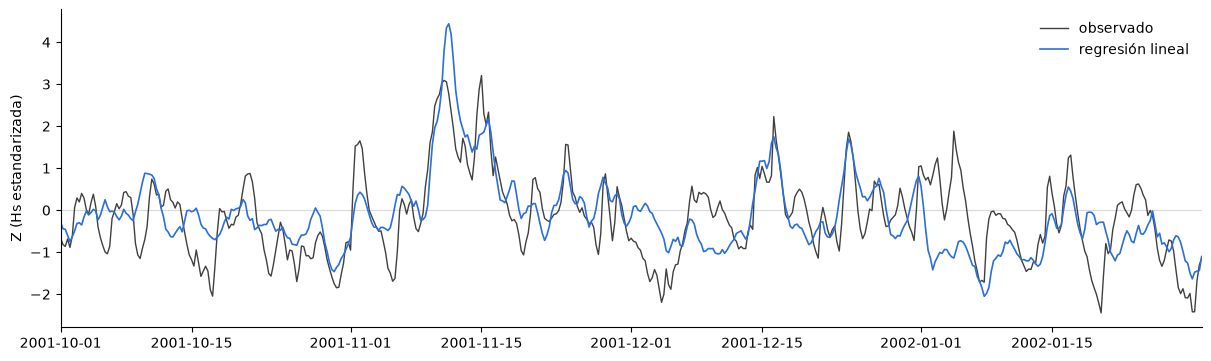

In [29]:
t0, t1 = "2001-10-01", "2002-01-31"

fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
ax.plot(y.loc[t0:t1], color="0.25", lw=1, label="observado")
ax.plot(f_oof.loc[t0:t1], color="#2a6fdb", lw=1.2, label="regresión lineal")
ax.axhline(0, color="0.85", lw=0.8, zorder=0)
ax.set(ylabel="Z (Hs estandarizada)", xlim=(pd.Timestamp(t0), pd.Timestamp(t1)))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
plt.show()

In [30]:
y_predict

time
1985-01-01 00:00:00    1.374522
1985-01-01 06:00:00    1.353291
1985-01-01 12:00:00    1.200192
1985-01-01 18:00:00    0.768704
1985-01-02 00:00:00    0.680315
                         ...   
2026-09-29 18:00:00   -0.260079
2026-09-30 00:00:00   -0.278521
2026-09-30 06:00:00   -0.317958
2026-09-30 12:00:00   -0.477312
2026-09-30 18:00:00   -0.367055
Length: 60992, dtype: float64

In [31]:
print(f"6-horaria: {y_predict.corr(y):.3f}")
print(f"6-horaria oof: {f_oof.corr(y):.3f}")
print(f"diaria:    {y_predict.resample('D').mean().corr(y.resample('D').mean()):.3f}")
print(f"diaria:    {f_oof.resample('D').mean().corr(y.resample('D').mean()):.3f}")

6-horaria: 0.648
6-horaria oof: 0.645
diaria:    0.673
diaria:    0.670


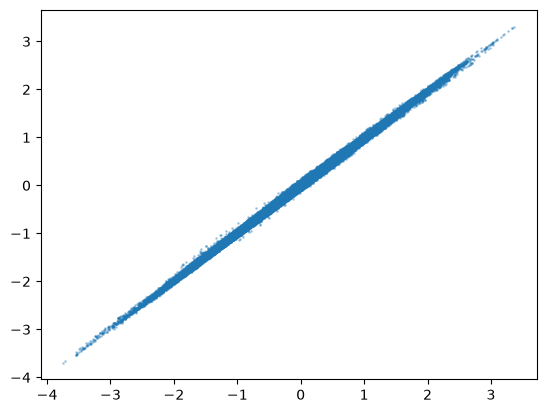

In [32]:
f_h_oof = f_oof.resample('h').interpolate()
r_h_off = (waves_df_z['VHM0'] - f_h_oof).dropna()

r_h_in = (waves_df_z['VHM0'] - y_predict.resample('h').interpolate()).dropna()

r = pd.concat({"oof": r_h_off, "in": r_h_in}, axis=1).dropna()
plt.scatter(r["oof"], r["in"], s=1, alpha=0.3)

In [33]:
import os, json
os.makedirs(f"outputs/linregs_pit_{point}", exist_ok=True)

#### Modelo final: coeficientes (portátil) + modelo completo
m_final.params.to_csv(f"outputs/linregs_pit_{point}/coeficientes.csv", header=["coef"])
m_final.save(f"outputs/linregs_pit_{point}/linreg_final.pickle", remove_data=True)
with open(f"outputs/linregs_pit_{point}/linreg_features.json", "w") as f:
    json.dump({"columns": list(m_final.params.index), "lags_h": lags, "train": ["1985-01-01", "2015-12-31"]}, f, indent=1)

#### Serie horaria: z, f y residuo (OOF en 1985–2015, modelo final en 2016–2025)
f_test = m_final.predict(sm.add_constant(X[~tr], has_constant="add"))
f_6h = pd.concat([f_oof, f_test]).sort_index()
f_h = f_6h.resample("h").interpolate()
z_h = waves_df_z['VHM0'].reindex(f_h.index)

residuos = pd.DataFrame({"z": z_h, "f": f_h, "r": z_h - f_h})
residuos["periodo"] = np.where(residuos.index < "2016-01-01", "oof", "test")
residuos.dropna(subset=["r"]).to_csv(f"outputs/linregs_pit_{point}/residuos_horarios.csv")
print(residuos.dropna().groupby("periodo")["r"].agg(["count", "std"]))

          count       std
periodo                  
oof      271728  0.767914
test      94219  0.764768
